<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/33_expansion_moran_lisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 33 · Moran global y LISA del uso agropecuario por celda

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿el uso agropecuario y su expansión están agrupados en el espacio, y dónde están los focos de expansión?

**Entradas:**
- `datos/comunes/grilla_2km.gpkg` (cuaderno 02, DVC).
- `datos/comunes/agro_celda.csv` (cuaderno 30, DVC).
- `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, DVC), solo para los mapas.

**Salidas** (en `modulos/expansion/resultados/` y `modulos/expansion/graficas/`):
- `33_moran_global.csv`, `33_alto_alto_municipio.csv`, `33_correlograma.csv`.
- `33_lisa_celdas.csv` (DVC): una fila por celda con su cuadrante LISA.
- `33_lisa_agro.png`, `33_correlograma.png`.

**Método:**
- Variables: (a) % agropecuario 2024 (`agro_pct_2024`) y (b) cambio 2000–2024 (`cambio_agro_pp`), en las celdas válidas del cuaderno 30.
- Vecindad reina (queen) de la grilla de 2 km: las 8 celdas que tocan a cada celda. Pesos estandarizados por fila. Es la misma vecindad del cuaderno 61.
- **I de Moran global** con 999 permutaciones. I > 0 significa que celdas vecinas se parecen (agrupamiento).
- **LISA** (Moran local) con 999 permutaciones y p < 0,05. Las celdas **alto–alto** son celdas altas rodeadas de celdas altas: en el cambio 2000–2024 son los focos de expansión.
- **Correlograma de Moran**: I por anillos de distancia de 4 km hasta 60 km, en una muestra de 4.000 celdas, para ver hasta qué distancia llega el agrupamiento.
- Con solo 7 municipios, el Moran municipal no tiene potencia, así que no se calcula.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import esda
import libpysal

SEMILLA = 2026
PERMUTACIONES = 999
ALFA = 0.05
VARIABLES = {'agro_pct_2024': '% agropecuario 2024', 'cambio_agro_pp': 'cambio 2000–2024 (pp)'}

print('Raíz del repo:', RAIZ)
print('esda', esda.__version__, '| libpysal', libpysal.__version__)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto
esda 2.9.0 | libpysal 4.14.1


c:\Users\mipip\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Paso 2. Datos y vecindad reina
Las coordenadas de cada celda salen de su `id_celda` (esquina inferior izquierda en km). Dos celdas son vecinas si están a 2 km en x, en y o en diagonal. Las celdas que quedan sin vecinas (islas) se quitan.

In [2]:
traer('datos/comunes/grilla_2km.gpkg')
traer('datos/comunes/agro_celda.csv')
traer('datos/comunes/altillanura_municipios.gpkg')

grilla = gpd.read_file(os.path.join(COMUNES, 'grilla_2km.gpkg')).to_crs(9377)
agro = pd.read_csv(os.path.join(COMUNES, 'agro_celda.csv'))
mpios = gpd.read_file(os.path.join(COMUNES, 'altillanura_municipios.gpkg')).to_crs(9377)

d = grilla.merge(agro, on='id_celda', how='inner')
d = d[d['celda_valida'].astype(bool)].dropna(subset=list(VARIABLES)).reset_index(drop=True)
partes = d['id_celda'].str.extract(r'x(\d+)_y(\d+)').astype(int)
d['x_km'], d['y_km'] = partes[0], partes[1]

pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
               if (dx or dy) and (x + dx, y + dy) in pos]
           for (x, y), k in pos.items()}
islas = [k for k, v in vecinos.items() if not v]
if islas:
    d = d.drop(index=islas).reset_index(drop=True)
    pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
    vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
                   if (dx or dy) and (x + dx, y + dy) in pos]
               for (x, y), k in pos.items()}

w = libpysal.weights.W(vecinos, silence_warnings=True)
w.transform = 'r'
print(f'Celdas válidas: {len(d):,} de {len(grilla):,} | islas quitadas: {len(islas)} | vecinas promedio: {w.mean_neighbors:.1f}')

Celdas válidas: 34,473 de 34,763 | islas quitadas: 0 | vecinas promedio: 7.9


## Paso 3. I de Moran global

In [3]:
np.random.seed(SEMILLA)
filas = []
for variable, etiqueta in VARIABLES.items():
    m = esda.Moran(d[variable].to_numpy(dtype=float), w, permutations=PERMUTACIONES)
    filas.append({'variable': variable, 'descripcion': etiqueta, 'n_celdas': len(d), 'I_moran': m.I,
                  'I_esperado': m.EI, 'p_permutacion': m.p_sim, 'permutaciones': PERMUTACIONES})
moran_global = pd.DataFrame(filas)
moran_global.round(5).to_csv(os.path.join(RESULTADOS, '33_moran_global.csv'), index=False)
print(moran_global.round(4).to_string(index=False))

      variable           descripcion  n_celdas  I_moran  I_esperado  p_permutacion  permutaciones
 agro_pct_2024   % agropecuario 2024     34473   0.7936        -0.0          0.001            999
cambio_agro_pp cambio 2000–2024 (pp)     34473   0.6019        -0.0          0.001            999


## Paso 4. LISA: dónde están los grupos
Cada celda significativa (p < 0,05 con 999 permutaciones) cae en un cuadrante:
- **Alto–alto**: valor alto rodeado de valores altos.
- **Bajo–bajo**: valor bajo rodeado de valores bajos.
- **Alto–bajo** y **bajo–alto**: celdas atípicas frente a sus vecinas.

Como se hace una prueba por celda, se reporta también cuántas celdas siguen siendo significativas con p < 0,01.

In [4]:
ETIQUETAS = {1: 'Alto–alto', 2: 'Bajo–alto', 3: 'Bajo–bajo', 4: 'Alto–bajo'}
lisa = pd.DataFrame({'id_celda': d['id_celda'], 'mpio_cdpmp': d['mpio_cdpmp'], 'municipio': d['mpio_cnmbr']})
conteos = []
for variable in VARIABLES:
    local = esda.Moran_Local(d[variable].to_numpy(dtype=float), w, permutations=PERMUTACIONES, seed=SEMILLA)
    cuadrante = pd.Series(np.where(local.p_sim < ALFA, local.q, 0)).map(ETIQUETAS).fillna('No significativo')
    lisa[f'lisa_{variable}'] = cuadrante.to_numpy()
    lisa[f'p_{variable}'] = local.p_sim
    conteo = lisa[f'lisa_{variable}'].value_counts()
    conteos.append({'variable': variable, **{e: int(conteo.get(e, 0)) for e in list(ETIQUETAS.values()) + ['No significativo']},
                    'alto_alto_p_0_01': int(((local.q == 1) & (local.p_sim < 0.01)).sum())})
conteos = pd.DataFrame(conteos)
lisa.round(4).to_csv(os.path.join(RESULTADOS, '33_lisa_celdas.csv'), index=False)
print(conteos.to_string(index=False))

columna = 'lisa_cambio_agro_pp'
por_mpio = (lisa.assign(alto_alto=lisa[columna] == 'Alto–alto')
            .groupby('municipio').agg(celdas=('id_celda', 'size'), alto_alto=('alto_alto', 'sum')))
por_mpio['pct_alto_alto'] = por_mpio['alto_alto'] / por_mpio['celdas'] * 100
por_mpio['pct_del_total_alto_alto'] = por_mpio['alto_alto'] / max(por_mpio['alto_alto'].sum(), 1) * 100
por_mpio = por_mpio.sort_values('alto_alto', ascending=False)
por_mpio.round(2).to_csv(os.path.join(RESULTADOS, '33_alto_alto_municipio.csv'))
print('\nFocos de expansión (alto–alto del cambio 2000–2024) por municipio:')
print(por_mpio.round(1).to_string())

      variable  Alto–alto  Bajo–alto  Bajo–bajo  Alto–bajo  No significativo  alto_alto_p_0_01
 agro_pct_2024       5071        308      14258         23             14813              3677
cambio_agro_pp       4135        560      11805        187             17786              2691

Focos de expansión (alto–alto del cambio 2000–2024) por municipio:
                celdas  alto_alto  pct_alto_alto  pct_del_total_alto_alto
municipio                                                                
PUERTO GAITÁN     4392       1023           23.3                     24.7
LA PRIMAVERA      4660        918           19.7                     22.2
MAPIRIPÁN         3129        702           22.4                     17.0
PUERTO CARREÑO    2972        587           19.8                     14.2
PUERTO LÓPEZ      1846        385           20.9                      9.3
SANTA ROSALÍA      940        282           30.0                      6.8
CUMARIBO         16534        238            1.4       

## Paso 5. Mapas de clústeres LISA

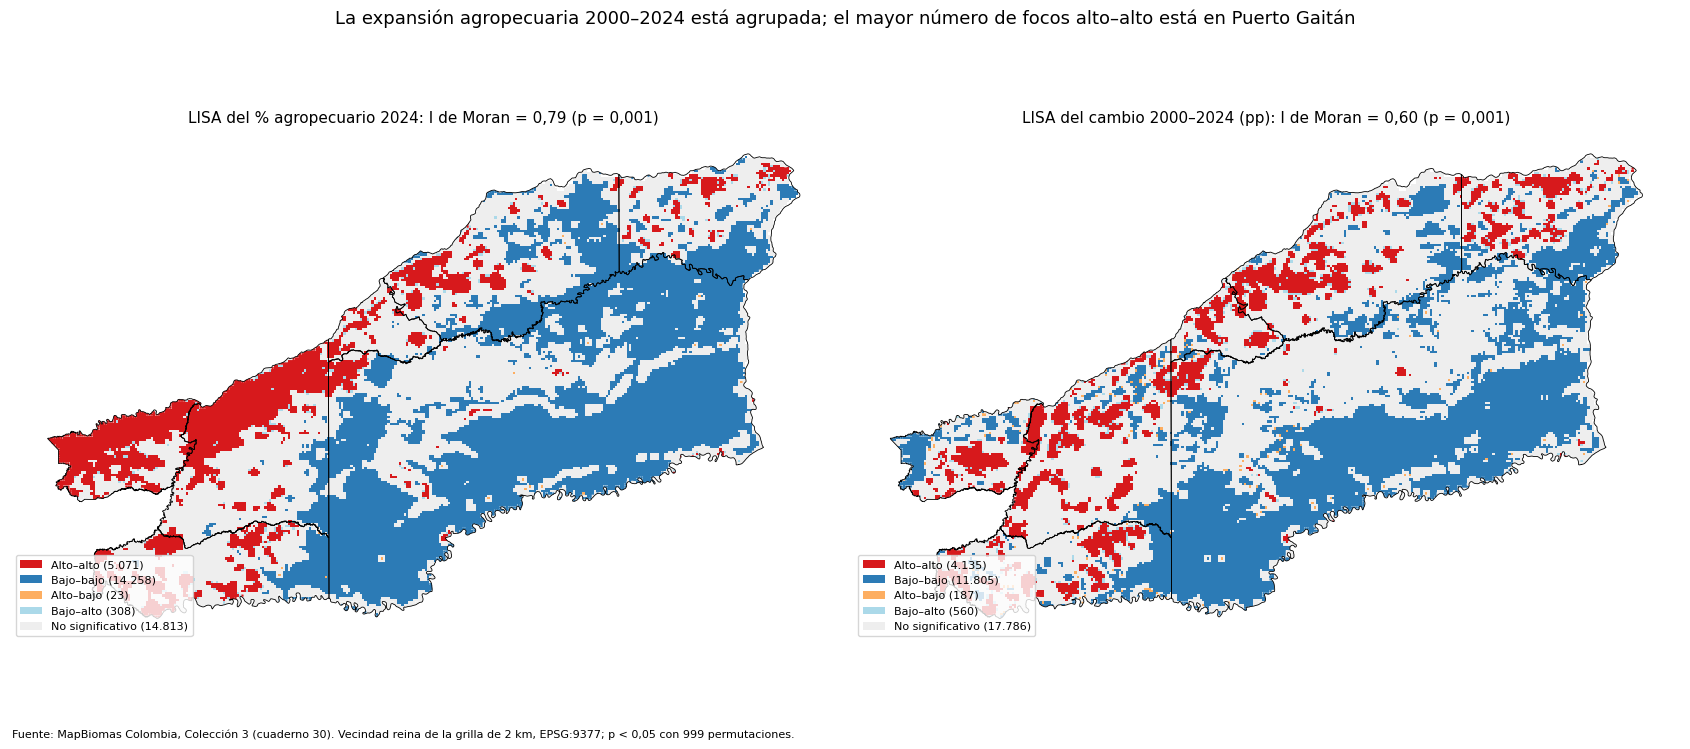

In [5]:
COLORES = {'Alto–alto': '#d7191c', 'Bajo–bajo': '#2c7bb6', 'Alto–bajo': '#fdae61',
           'Bajo–alto': '#abd9e9', 'No significativo': '#eeeeee'}
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, variable in zip(axes, VARIABLES):
    for etiqueta, color in COLORES.items():
        sub = d[lisa[f'lisa_{variable}'].to_numpy() == etiqueta]
        if len(sub):
            sub.plot(ax=ax, color=color, linewidth=0, label=f'{etiqueta} ({coma(len(sub), 0)})')
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    fila = moran_global.set_index('variable').loc[variable]
    ax.set_title(f'LISA del {VARIABLES[variable]}: I de Moran = {coma(fila.I_moran, 2)} (p = {coma(fila.p_permutacion, 3)})', fontsize=11)
    ax.legend(fontsize=8, loc='lower left')
    ax.set_axis_off()
principal = por_mpio.index[0].title() if por_mpio['alto_alto'].iloc[0] > 0 else 'ningún municipio'
fig.suptitle(f'La expansión agropecuaria 2000–2024 está agrupada; el mayor número de focos alto–alto está en {principal}', fontsize=13)
fig.text(0.01, 0.01, 'Fuente: MapBiomas Colombia, Colección 3 (cuaderno 30). Vecindad reina de la grilla de 2 km, EPSG:9377; '
         'p < 0,05 con 999 permutaciones.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '33_lisa_agro.png'), dpi=150, bbox_inches='tight')
plt.show()

## Paso 6. Correlograma de Moran por distancia
I de Moran con pesos binarios por anillos de 4 km (0–4, 4–8, …, 56–60 km) en una muestra aleatoria de 4.000 celdas válidas. El valor p de cada anillo sale de 199 permutaciones de los valores entre las celdas de la muestra. Donde la curva cruza el valor esperado (≈ 0) termina el agrupamiento.

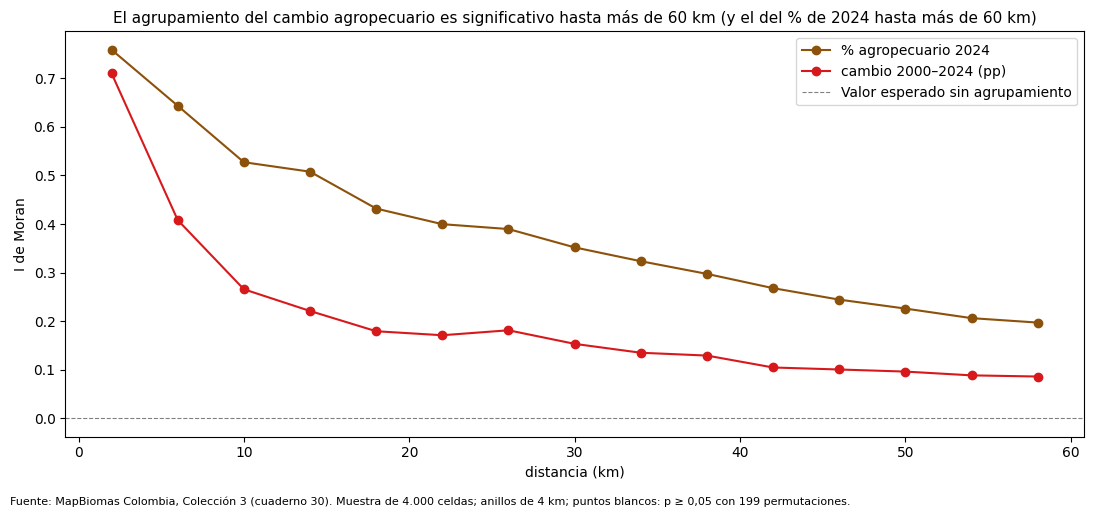

In [6]:
ANILLO_KM = 4
MAX_KM = 60
PERMUTACIONES_ANILLO = 199
rng = np.random.default_rng(SEMILLA)
m = min(4000, len(d))
muestra = rng.choice(len(d), m, replace=False)
xy = d[['x_km', 'y_km']].to_numpy(dtype=float)[muestra] + 1.0
pares = cKDTree(xy).query_pairs(MAX_KM, output_type='ndarray')
i, j = pares[:, 0], pares[:, 1]
anillo = np.minimum((np.hypot(*(xy[i] - xy[j]).T) // ANILLO_KM).astype(int), MAX_KM // ANILLO_KM - 1)
n_anillos = MAX_KM // ANILLO_KM
pares_por_anillo = np.bincount(anillo, minlength=n_anillos)

def moran_anillos(z):
    suma = np.bincount(anillo, weights=z[i] * z[j], minlength=n_anillos)
    return np.divide(m * suma, pares_por_anillo * (z @ z), out=np.full(n_anillos, np.nan), where=pares_por_anillo > 0)

filas = []
for variable in VARIABLES:
    v = d[variable].to_numpy(dtype=float)[muestra]
    z = v - v.mean()
    observado = moran_anillos(z)
    simulados = np.array([moran_anillos(rng.permutation(z)) for _ in range(PERMUTACIONES_ANILLO)])
    mayores = (np.abs(simulados) >= np.abs(observado)).sum(axis=0)
    p = (mayores + 1) / (PERMUTACIONES_ANILLO + 1)
    for k in range(n_anillos):
        filas.append({'variable': variable, 'desde_km': k * ANILLO_KM, 'hasta_km': (k + 1) * ANILLO_KM,
                      'pares': int(pares_por_anillo[k]), 'I_moran': observado[k], 'p_permutacion': p[k]})
correlograma = pd.DataFrame(filas)
correlograma.round(5).to_csv(os.path.join(RESULTADOS, '33_correlograma.csv'), index=False)

fig, ax = plt.subplots(figsize=(11, 5))
alcance = {}
for variable, color in zip(VARIABLES, ('#8c510a', '#d7191c')):
    t = correlograma[correlograma['variable'] == variable]
    centro = (t['desde_km'] + t['hasta_km']) / 2
    ax.plot(centro, t['I_moran'], color=color, marker='o', label=VARIABLES[variable])
    no_sig = t['p_permutacion'] >= ALFA
    ax.scatter(centro[no_sig], t.loc[no_sig, 'I_moran'], s=70, facecolors='white', edgecolors=color, zorder=3)
    seguidos = ((t['I_moran'] > 0) & (t['p_permutacion'] < ALFA)).to_numpy()
    k = len(seguidos) if seguidos.all() else int(np.argmin(seguidos))
    if k == len(seguidos):
        alcance[variable] = f'más de {MAX_KM} km'
    elif k == 0:
        alcance[variable] = 'menos de 4 km'
    else:
        alcance[variable] = f'unos {int(t["hasta_km"].iloc[k - 1])} km'
ax.axhline(-1 / (m - 1), color='grey', linestyle='--', linewidth=0.8, label='Valor esperado sin agrupamiento')
ax.set_xlabel('distancia (km)')
ax.set_ylabel('I de Moran')
ax.legend()
ax.set_title(f'El agrupamiento del cambio agropecuario es significativo hasta {alcance["cambio_agro_pp"]} '
             f'(y el del % de 2024 hasta {alcance["agro_pct_2024"]})', fontsize=11)
fig.text(0.01, -0.02, f'Fuente: MapBiomas Colombia, Colección 3 (cuaderno 30). Muestra de {coma(m, 0)} celdas; anillos de {ANILLO_KM} km; '
         f'puntos blancos: p ≥ 0,05 con {PERMUTACIONES_ANILLO} permutaciones.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '33_correlograma.png'), dpi=150, bbox_inches='tight')
plt.show()

## Límites
- LISA hace una prueba por celda; con miles de celdas, algunas salen significativas por azar. Por eso se reporta también el conteo con p < 0,01.
- El resultado depende de la vecindad elegida (reina de 2 km). El correlograma muestra cómo cambia el agrupamiento con la distancia.
- El cambio 2000–2024 compara dos años; no dice cuándo ocurrió la expansión dentro del periodo.
- El uso agropecuario incluye el mosaico de agricultura y pastos, así que mezcla cultivos y ganadería.

## Resumen para el informe

In [7]:
for _, f in moran_global.iterrows():
    print(f'{f.descripcion}: I de Moran = {coma(f.I_moran, 3)} (p = {coma(f.p_permutacion, 3)}, '
          f'{PERMUTACIONES} permutaciones, {coma(f.n_celdas, 0)} celdas).')
c = conteos.set_index('variable').loc['cambio_agro_pp']
print(f'Focos de expansión (alto–alto del cambio 2000–2024): {coma(c["Alto–alto"], 0)} celdas con p < 0,05 '
      f'({coma(c["alto_alto_p_0_01"], 0)} con p < 0,01).')
print('Por municipio:', '; '.join(f'{n.title()}: {coma(r.alto_alto, 0)} ({coma(r.pct_del_total_alto_alto)} %)' for n, r in por_mpio.iterrows()))
print(f'Alcance del agrupamiento (correlograma): cambio hasta {alcance["cambio_agro_pp"]}; % de 2024 hasta {alcance["agro_pct_2024"]}.')

% agropecuario 2024: I de Moran = 0,794 (p = 0,001, 999 permutaciones, 34.473 celdas).
cambio 2000–2024 (pp): I de Moran = 0,602 (p = 0,001, 999 permutaciones, 34.473 celdas).
Focos de expansión (alto–alto del cambio 2000–2024): 4.135 celdas con p < 0,05 (2.691 con p < 0,01).
Por municipio: Puerto Gaitán: 1.023 (24,7 %); La Primavera: 918 (22,2 %); Mapiripán: 702 (17,0 %); Puerto Carreño: 587 (14,2 %); Puerto López: 385 (9,3 %); Santa Rosalía: 282 (6,8 %); Cumaribo: 238 (5,8 %)
Alcance del agrupamiento (correlograma): cambio hasta más de 60 km; % de 2024 hasta más de 60 km.
